<a href="https://colab.research.google.com/github/TamannaSwarna140/Diabetes-Prediction/blob/main/Diabetes_Prediction_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Risk Prediction on the Pima Indians Dataset

**Author:** Tamanna Akter Swarna

This project predicts whether a patient tested positive for diabetes from eight clinical measurements. It began as a university
project in 2023; this notebook is a rebuilt version with data-quality handling, repeated cross-validation, a wider set of metrics
and an analysis of the decision threshold.

> This is a learning project on a small public dataset. It is not a diagnostic tool and should not be used for medical decisions.

## Summary of results


**Data:** 768 women aged 21 or older of Pima Indian heritage; 268 tested positive (34.9%). Always predicting "negative" gives 65.1% accuracy.

**Data quality:** Zeros in glucose, blood pressure, skin thickness, insulin and BMI are impossible values (missing data): 376 rows (49.0%) are affected. They are treated as missing and imputed inside each cross-validation fold.

**Evaluation:** 5-fold cross-validation repeated 10 times (50 fits per model). A single 80/20 split is shown to be unreliable: its accuracy ranges from 70.1% to 82.5% across 100 random splits.

**Model comparison:** Logistic regression, linear SVM and random forest tie at ROC-AUC 0.835; accuracy is 76-77% for all three. A depth-4 decision tree is weaker (ROC-AUC 0.785).

**Chosen model:** Logistic regression: accuracy 76.7%, ROC-AUC 0.835, with inspectable coefficients.

**Threshold trade-off:** At the default 0.5 cut-off the model catches 57% of positive cases. Lowering it to 0.3 raises sensitivity to 79% at the cost of specificity (70%) and precision (59%).

**Main drivers:** Glucose by a wide margin, then BMI, number of pregnancies, diabetes pedigree function and age.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

## 2. Data

The Pima Indians Diabetes dataset comes from the National Institute of Diabetes and Digestive and Kidney Diseases. All 768 patients
are women at least 21 years old of Pima Indian heritage. The target `Outcome` is 1 for a patient who tested positive for diabetes
and 0 otherwise. The eight features are `Pregnancies`, `Glucose` (2-hour plasma glucose), `BloodPressure` (diastolic),
`SkinThickness` (triceps), `Insulin` (2-hour serum), `BMI`, `DiabetesPedigreeFunction` and `Age`.

In [2]:
DATA_PATH = "data/diabetes.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "diabetes.csv"   # fallback: file uploaded next to the notebook

df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
print("Missing values (NaN):", int(df.isna().sum().sum()))
n_pos = int(df["Outcome"].sum())
print(f"Positive: {n_pos} ({df['Outcome'].mean():.1%}) | Negative: {len(df) - n_pos}")
print(f"Majority-class baseline accuracy: {1 - df['Outcome'].mean():.1%}")
df.describe().round(2)

Rows, columns: (768, 9)
Missing values (NaN): 0
Positive: 268 (34.9%) | Negative: 500
Majority-class baseline accuracy: 65.1%


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


### 2.1 Data quality: zeros that cannot be real
The table shows no missing values, but the minimum of several columns is 0. A glucose, blood pressure, skin thickness,
insulin or BMI of zero is physiologically impossible, so these zeros mark measurements that were not recorded.

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11

Rows with at least one impossible zero: 376 (49.0%)


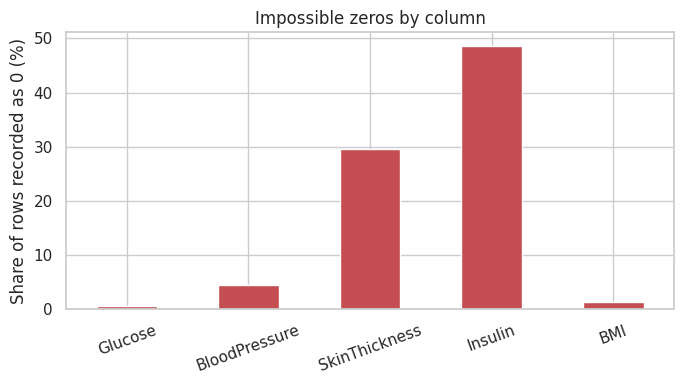

In [3]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_cols] == 0).sum()
print(zero_counts.to_string())
print(f"\nRows with at least one impossible zero: {(df[zero_cols] == 0).any(axis=1).sum()} "
      f"({(df[zero_cols] == 0).any(axis=1).mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 4))
(zero_counts / len(df) * 100).plot(kind="bar", color="#C44E52", rot=20, ax=ax)
ax.set_ylabel("Share of rows recorded as 0 (%)")
ax.set_title("Impossible zeros by column")
plt.tight_layout()
plt.savefig("images/01_impossible_zeros.png", dpi=150)
plt.show()

# Treat the impossible zeros as missing values
data = df.copy()
data[zero_cols] = data[zero_cols].replace(0, np.nan)
X = data.drop(columns="Outcome")
y = data["Outcome"]

**Finding:** Insulin is missing for 374 patients (48.7%) and skin thickness for 227 (29.6%); blood pressure (35), BMI (11) and glucose (5)
are much less affected. In total 376 rows (49.0%) have at least one impossible zero. The zeros are converted to missing values and imputed with the column median
inside each cross-validation fold (so imputation never uses test-fold information). `Pregnancies` can legitimately be 0 and is left unchanged.

## 3. Exploratory analysis

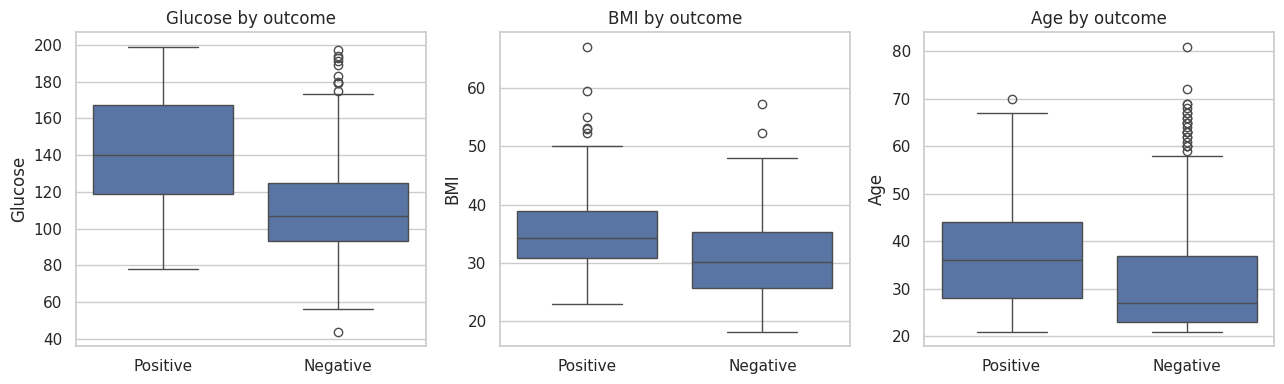

Median by outcome:
         Glucose   BMI   Age  Pregnancies  Insulin
Outcome                                           
0          107.0  30.1  27.0          2.0    102.5
1          140.0  34.3  36.0          4.0    169.5

Correlation with Outcome (missing values ignored pairwise):
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.boxplot(data=data, x=data["Outcome"].map({0: "Negative", 1: "Positive"}), y=col, ax=ax)
    ax.set_xlabel("")
    ax.set_title(f"{col} by outcome")
plt.tight_layout()
plt.savefig("images/02_features_by_outcome.png", dpi=150)
plt.show()

print("Median by outcome:")
print(data.groupby("Outcome")[["Glucose", "BMI", "Age", "Pregnancies", "Insulin"]].median().round(1))
print("\nCorrelation with Outcome (missing values ignored pairwise):")
print(data.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3).to_string())

**Finding:** Patients who tested positive have markedly higher glucose (median 140 against 107), higher BMI (34.3 against 30.1)
and are older (median 36 against 27). Glucose has the strongest correlation with the outcome (0.50), followed by BMI (0.31),
insulin (0.30), skin thickness (0.26), age (0.24) and pregnancies (0.22).

## 4. Why a single train/test split is not enough

The dataset has 768 rows, so an 80/20 split tests on only 154 patients. To see how much the result depends on which patients land in
the test set, a linear SVM is evaluated on 100 different random splits.

Accuracy over 100 splits: mean 0.763, std 0.026, min 0.701, max 0.825


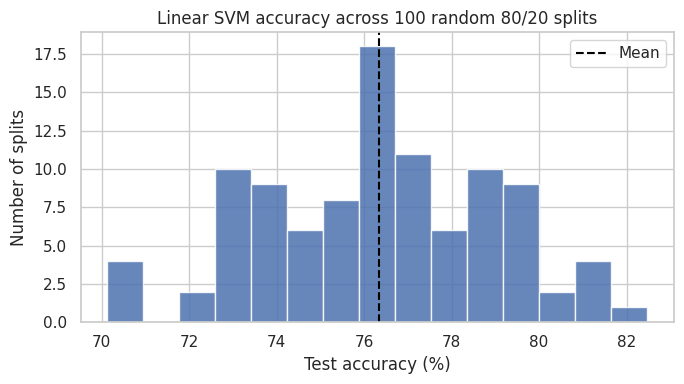

In [5]:
def make_pipeline(clf, scale=True):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("clf", clf))
    return Pipeline(steps)

split_acc = []
for s in range(100):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=s)
    m = make_pipeline(SVC(kernel="linear")).fit(X_tr, y_tr)
    split_acc.append(accuracy_score(y_te, m.predict(X_te)))
split_acc = np.array(split_acc)
print(f"Accuracy over 100 splits: mean {split_acc.mean():.3f}, std {split_acc.std():.3f}, "
      f"min {split_acc.min():.3f}, max {split_acc.max():.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(split_acc * 100, bins=15, color="#4C72B0", alpha=0.85)
ax.axvline(split_acc.mean() * 100, color="black", linestyle="--", label="Mean")
ax.set_xlabel("Test accuracy (%)")
ax.set_ylabel("Number of splits")
ax.set_title("Linear SVM accuracy across 100 random 80/20 splits")
ax.legend()
plt.tight_layout()
plt.savefig("images/03_split_variability.png", dpi=150)
plt.show()

**Finding:** The same model scores anywhere from 70.1% to 82.5% depending on the split (mean 76.3%, standard deviation 2.6 points). Differences of one to
three points between models on one split are therefore within chance, and a single split cannot rank them. The models below are compared with 5-fold
cross-validation repeated 10 times, which averages over 50 different test sets.

## 5. Model comparison

Six models are compared. Imputation and scaling (for the distance- and margin-based models) are part of each pipeline, so they are fitted on
training folds only. Tree-based models do not need scaling.

In [6]:
models = {
    "Logistic regression": make_pipeline(LogisticRegression(max_iter=1000)),
    "Linear SVM": make_pipeline(SVC(kernel="linear")),
    "KNN (k=15)": make_pipeline(KNeighborsClassifier(n_neighbors=15)),
    "Decision tree (depth 4)": make_pipeline(DecisionTreeClassifier(max_depth=4, random_state=SEED), scale=False),
    "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                          random_state=SEED, n_jobs=-1), scale=False),
    "Gradient boosting": make_pipeline(GradientBoostingClassifier(random_state=SEED), scale=False),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
rows = []
for name, model in models.items():
    r = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                       scoring=["accuracy", "roc_auc", "recall", "precision", "f1"])
    rows.append({
        "Model": name,
        "Accuracy": r["test_accuracy"].mean(), "Accuracy std": r["test_accuracy"].std(),
        "ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC std": r["test_roc_auc"].std(),
        "Recall": r["test_recall"].mean(), "Precision": r["test_precision"].mean(), "F1": r["test_f1"].mean(),
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
display(results)

,Accuracy,Accuracy std,ROC-AUC,ROC-AUC std,Recall,Precision,F1
Model,,,,,,,
Logistic regression,0.767,0.029,0.835,0.027,0.558,0.713,0.624
Linear SVM,0.764,0.028,0.835,0.028,0.545,0.712,0.615
KNN (k=15),0.759,0.026,0.824,0.025,0.571,0.690,0.623
Decision tree (depth 4),0.734,0.034,0.785,0.036,0.646,0.622,0.626
Random forest,0.762,0.022,0.835,0.026,0.592,0.686,0.634
Gradient boosting,0.757,0.023,0.828,0.026,0.601,0.670,0.632


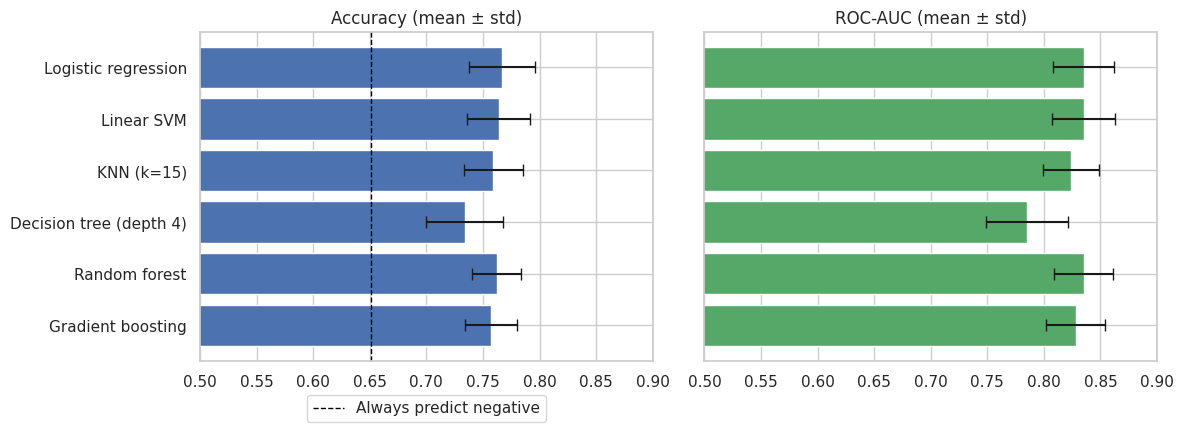

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].barh(results.index, results["Accuracy"], xerr=results["Accuracy std"], color="#4C72B0", capsize=4)
axes[0].axvline(0.651, color="black", linestyle="--", linewidth=1, label="Always predict negative")
axes[0].set_xlim(0.5, 0.9)
axes[0].set_title("Accuracy (mean ± std)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08))
axes[1].barh(results.index, results["ROC-AUC"], xerr=results["ROC-AUC std"], color="#55A868", capsize=4)
axes[1].set_xlim(0.5, 0.9)
axes[1].set_title("ROC-AUC (mean ± std)")
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig("images/04_model_comparison.png", dpi=150)
plt.show()

**Finding:** Logistic regression (76.7% accuracy, ROC-AUC 0.835), linear SVM (76.4%, 0.835) and random forest (76.2%, 0.835) are indistinguishable:
their differences are far smaller than the fold-to-fold spread (about 0.03). KNN (75.9%, 0.824) and gradient boosting (75.7%, 0.828) are close behind.
The depth-4 decision tree is weaker on ranking quality (ROC-AUC 0.785) although it has the highest recall (0.65) at the default threshold, at the cost of precision.
All models beat the 65.1% majority baseline by about 11 points; none exceeds roughly 77%, which points to a ceiling set by the features and the
small sample rather than by the algorithm.

**Model choice:** logistic regression. It performs as well as the more complex models, is fast, and its coefficients are directly interpretable.

### 5.1 Effect of handling the impossible zeros
The same logistic regression is compared with the zeros left in place and with the zeros imputed.

In [8]:
cv_cmp = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
for label, features in [("Zeros left as 0", df.drop(columns="Outcome")), ("Zeros imputed (median)", X)]:
    r = cross_validate(models["Logistic regression"], features, y, cv=cv_cmp, n_jobs=-1,
                       scoring=["accuracy", "roc_auc"])
    print(f"{label:24s} accuracy {r['test_accuracy'].mean():.3f} | ROC-AUC {r['test_roc_auc'].mean():.3f}")

Zeros left as 0          accuracy 0.771 | ROC-AUC 0.829
Zeros imputed (median)   accuracy 0.767 | ROC-AUC 0.835


**Finding:** Imputing the zeros changes performance very little (ROC-AUC 0.829 with zeros left in, 0.835 with imputation).
The correction matters for correctness, since a zero glucose reading should never be treated as a real value, but it is not what limits the model.

## 6. Out-of-fold performance of the chosen model

Every patient is predicted by a model that never saw that patient (5-fold out-of-fold predictions), so the full dataset is used for evaluation.

Out-of-fold ROC-AUC: 0.835


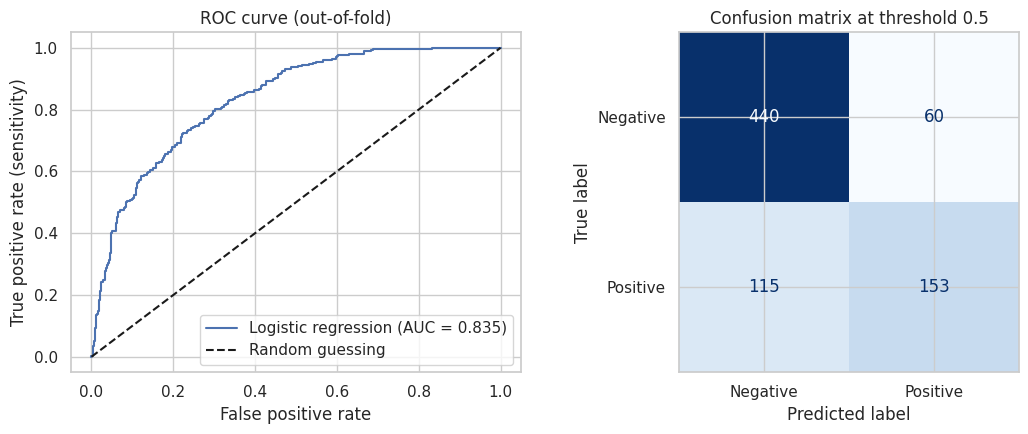

In [9]:
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
best = models["Logistic regression"]
proba = cross_val_predict(best, X, y, cv=cv_oof, method="predict_proba")[:, 1]
print(f"Out-of-fold ROC-AUC: {roc_auc_score(y, proba):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y, proba)
axes[0].plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (sensitivity)")
axes[0].set_title("ROC curve (out-of-fold)")
axes[0].legend()
ConfusionMatrixDisplay(confusion_matrix(y, proba >= 0.5), display_labels=["Negative", "Positive"]).plot(
    cmap="Blues", values_format="d", ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix at threshold 0.5")
plt.tight_layout()
plt.savefig("images/05_roc_confusion.png", dpi=150)
plt.show()

**Finding:** At the default 0.5 threshold the model correctly identifies 153 of 268 positive patients (sensitivity 0.57) and 440 of 500 negative patients
(specificity 0.88), for an accuracy of 77.2%. It misses 115 patients who tested positive, which is the costly error in a screening setting.
For context, the dataset's documentation reports 76% sensitivity and specificity for the original ADAP algorithm on 192 held-out instances;
the protocols differ, but the results are in the same range.

## 7. Choosing the decision threshold

Accuracy hides the trade-off between missing positive cases and raising false alarms. Lowering the threshold flags more patients as at risk:

,Sensitivity,Specificity,Precision,Accuracy,Patients flagged,Missed positives,False alarms
Threshold,,,,,,,
0.50,0.571,0.880,0.718,0.772,0.277,115,60
0.40,0.664,0.810,0.652,0.759,0.355,90,95
0.35,0.728,0.766,0.625,0.753,0.406,73,117
0.30,0.787,0.704,0.588,0.733,0.467,57,148
0.25,0.836,0.652,0.563,0.716,0.518,44,174


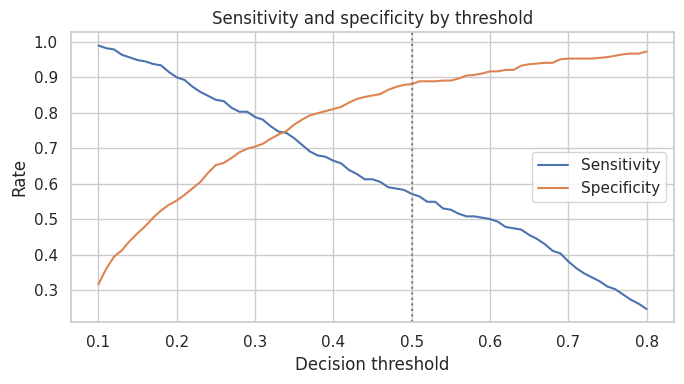

In [10]:
rows = []
for t in [0.50, 0.40, 0.35, 0.30, 0.25]:
    pred = proba >= t
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    rows.append({"Threshold": t, "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
                 "Precision": tp / (tp + fp), "Accuracy": (tp + tn) / len(y),
                 "Patients flagged": pred.mean(), "Missed positives": fn, "False alarms": fp})
thr = pd.DataFrame(rows).set_index("Threshold").round(3)
display(thr)

ts = np.linspace(0.1, 0.8, 71)
sens = [((proba >= t) & (y == 1)).sum() / (y == 1).sum() for t in ts]
spec = [((proba < t) & (y == 0)).sum() / (y == 0).sum() for t in ts]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ts, sens, label="Sensitivity")
ax.plot(ts, spec, label="Specificity")
ax.axvline(0.5, color="grey", linestyle=":")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Rate")
ax.set_title("Sensitivity and specificity by threshold")
ax.legend()
plt.tight_layout()
plt.savefig("images/06_threshold_tradeoff.png", dpi=150)
plt.show()

**Finding:** Moving the threshold from 0.5 to 0.3 raises sensitivity from 0.57 to 0.79 and cuts missed positives from 115 to 57. In exchange, specificity falls from
0.88 to 0.70 and false alarms rise from 60 to 148; 47% of patients would be flagged instead of 28%. The right threshold depends on the relative cost of a missed
case against an unnecessary follow-up test, which this dataset cannot tell us. For a screening use, a threshold near 0.3 to 0.35 would be the natural place to start.

## 8. What drives the predictions

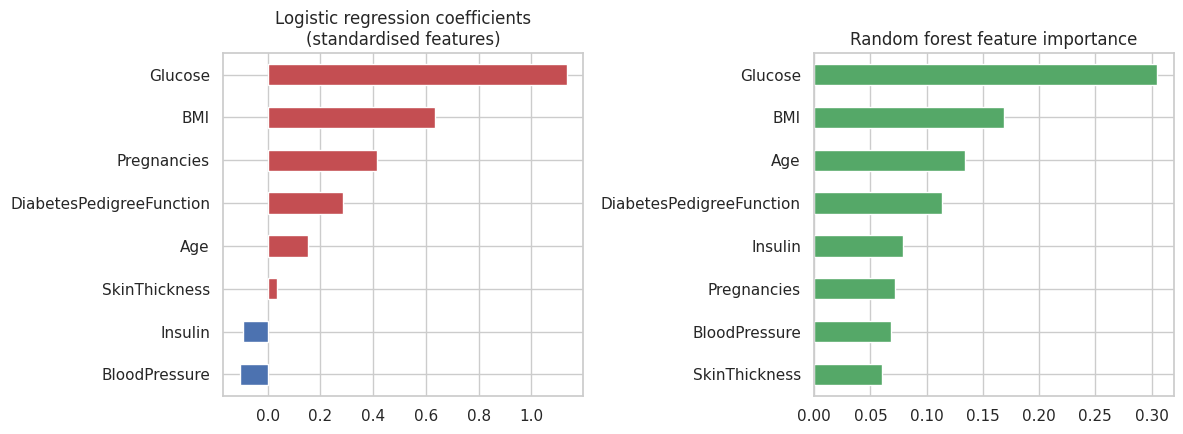

Glucose                     1.13
BMI                         0.64
Pregnancies                 0.41
DiabetesPedigreeFunction    0.29
Age                         0.15
SkinThickness               0.04
Insulin                    -0.09
BloodPressure              -0.11


In [11]:
final = make_pipeline(LogisticRegression(max_iter=1000)).fit(X, y)
coefs = pd.Series(final.named_steps["clf"].coef_[0], index=X.columns).sort_values()

rf_final = make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
                         scale=False).fit(X, y)
imp = pd.Series(rf_final.named_steps["clf"].feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
coefs.plot(kind="barh", color=["#4C72B0" if v < 0 else "#C44E52" for v in coefs], ax=axes[0])
axes[0].set_title("Logistic regression coefficients\n(standardised features)")
imp.plot(kind="barh", color="#55A868", ax=axes[1])
axes[1].set_title("Random forest feature importance")
plt.tight_layout()
plt.savefig("images/07_feature_drivers.png", dpi=150)
plt.show()
print(coefs.round(2).sort_values(ascending=False).to_string())

**Finding:** Both models rank glucose first by a wide margin (logistic coefficient 1.13; random forest importance 0.31). BMI (0.64; 0.17) and
the number of pregnancies (0.41) follow in the regression, with diabetes pedigree function (0.29) and age (0.15) next; in the forest, age (0.13)
and pedigree function (0.11) come third and fourth. Insulin, skin thickness and blood pressure contribute little, which is notable because insulin and skin thickness are the
columns with the most missing values. These are associations in this sample, not causal effects.

## 9. Conclusions

### Findings
- Logistic regression reaches 76.7% accuracy and 0.835 ROC-AUC in repeated cross-validation, matching a linear SVM and a random forest. About 77% appears to be the
  ceiling for these eight features on this sample.
- Roughly half of the rows contain impossible zeros that stand for missing measurements. Correcting this is good practice but changed results only slightly.
- A single 80/20 split can give anything from 70.1% to 82.5% accuracy for the same model, so model comparisons need repeated cross-validation.
- At the default threshold the model misses 43% of positive cases; lowering the threshold to 0.3 catches 79% at the cost of more false alarms.
- Glucose is by far the strongest predictor, followed by BMI, pregnancies, pedigree function and age.

### Limitations
- Small dataset (768 patients), all women aged 21 or older of Pima Indian heritage. Results should not be assumed to hold for other populations.
- The outcome and the measurements come from a research study, not from routine screening, so real-world performance is unknown.
- Imputation used the median; insulin is missing for nearly half the patients, so a more careful approach could change feature importance.
- No external validation set and no hyperparameter tuning beyond fixed reasonable settings.
- The model identifies associations, not causes, and is not a diagnostic tool.

### Next steps
- Tune hyperparameters with nested cross-validation and compare multiple imputation or missing-value indicators.
- Calibrate the predicted probabilities and choose the threshold from clinical costs.
- Validate on a different diabetes dataset to test whether the model transfers beyond this population.